In [ ]:
import pandas as pd
import numpy as np
import cupy as cp
import matplotlib.pyplot as plt
import torch
import time
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler
from torch import nn
from torch.utils.data import DataLoader
import torch.nn as nn
from scipy.spatial.distance import cdist

# Problem statement

#### Classification problem using ML
#### 4 000 observations, 7 numerical features, 7 classes

In [ ]:
data = pd.read_csv('MLoGPU_data3_train.csv', sep=",", header=None)
features = data.iloc[:, :-1]
labels = data.iloc[:, -1]

In [ ]:
# train and test data split
features.head(5)

,0,1,2,3,4,5,6
0,0.147035,1.264512,-0.474615,-0.543303,-1.091289,0.590143,-1.599582
1,0.559923,1.935253,-2.557251,-0.743111,-0.696480,-0.085936,-1.899705
2,0.766367,-0.496182,0.373866,0.170298,-0.544630,-0.592996,0.634732
3,-1.642146,0.426087,0.913809,1.397691,1.338306,-0.818356,0.367963
4,-0.334668,0.090717,1.608021,0.627002,2.644213,-0.367636,1.234998


In [ ]:
# class distribution
labels.value_counts() # severe class imbalance

,count
7,
4.0,1746
3.0,1317
5.0,664
2.0,133
6.0,119
1.0,18
7.0,3


# Requirements

*   use of CUDA kernels with Rawkernel function in CuPy
*   use of Cupy and Pytorch library functions
*    methods implemented by you or your pair





# K-nearest-neighbor

*   realise a high-performance implementation of the method and show the advantage of using a CPU
### Required
*   computing the distances between the observations by a CUDA kernel
*   implementing the other logic for the method in Python with functionality offered by the CUPY library
*   timing of method execution and comparing the result to a central processing unit CPU implementation



In [ ]:
# Computing the distances using CUDA kernal - MAIN
kernel1 = cp.RawKernel(r''' extern "C"
  __global__ void calcu_distance(
    const double* data, const double* ref,
    double* dist_matrix, int num_rows_d,
    int num_rows_ref,
    int num_feat)
    {
    // tr_i for data, ts_i for the ref
    int tr_i = blockIdx.x * blockDim.x + threadIdx.x;
    int ts_i = blockIdx.y * blockDim.y + threadIdx.y;
    if (tr_i < num_rows_d && ts_i < num_rows_ref) {
      double sum = 0.0;
      for (int k = 0; k < num_feat; k++) {
        double diff = data[tr_i * num_feat + k] - ref[ts_i * num_feat + k];
        sum = sum + diff * diff;
      }
      dist_matrix[ts_i * num_rows_d + tr_i] = sqrt(sum);
    }
  }
''', 'calcu_distance')


In [ ]:
kernel2 = cp.RawKernel(r''' extern "C"
  __global__ void calcu_distance(
    const double* data, const double* ref,
    double* dist_matrix, int num_rows_d,
    int num_rows_ref,
    int num_feat)
    {
    extern __shared__ double shared_data[];
    // tr_i for data, ts_i for the ref
    int tx = threadIdx.x;
    int ty = threadIdx.y;
    int tr_i = blockIdx.x * blockDim.x + threadIdx.x;
    int ts_i = blockIdx.y * blockDim.y + threadIdx.y;
    if (ty == 0 && tr_i < num_rows_d) {
        for (int k = 0; k < num_feat; k++) {
            shared_data[tx * num_feat + k] = data[tr_i * num_feat + k];
        }
    }
    __syncthreads();
    if (tr_i < num_rows_d && ts_i < num_rows_ref) {
          double sum = 0.0;
          for (int k = 0; k < num_feat; k++) {
              double diff = data[tr_i * num_feat + k] - ref[ts_i * num_feat + k];
              sum += diff * diff;
          }
          dist_matrix[ts_i * num_rows_d + tr_i] = sqrt(sum);
      }
  }
''', 'calcu_distance')

In [ ]:
# KNN class
class KNN:
    def __init__(self, k, shared):
        self.k = k
        self.shared = shared
        self.scaler = StandardScaler()
    def fit(self,x,y):
        # scale the features
        self.scaler.fit(x)
        self.X_train = self.scaler.transform(x)
        self.threads = 32
        self.vector_len = np.int32(self.X_train.shape[0])
        self.num_feat = np.int32(self.X_train.shape[1])
        self.num_blocks_tr = int(np.ceil(self.vector_len / self.threads))
        self.y_train = y
    def predict(self, X_test):
        # estimate the class
        X_test = self.scaler.transform(X_test)
        self.test_len = np.int32(X_test.shape[0])
        self.num_blocks_tst = int(np.ceil(self.test_len / self.threads))
        predictions = []
        executions_times = []
        # transform data
        a = cp.asarray(self.X_train, order='C')
        b = cp.asarray(X_test, order='C')
        dist = cp.zeros((self.test_len, self.vector_len), dtype=cp.float64)
        y_train = cp.asarray(self.y_train.values.flatten())
        # actually no need for iteration : TO DO LOAD EVERYTHING AT ONCE
        if self.shared :
          shared_mem_size = self.threads * self.num_feat * 8 # bytes
          kernel2(
                (self.num_blocks_tr,self.num_blocks_tst,1),
                (self.threads,self.threads,1),
                (a, b, dist, self.vector_len, self.test_len, self.num_feat),shared_mem=shared_mem_size
          )
          # after warm-up start timer
          cp.cuda.Stream.null.synchronize()
          start_time = cp.cuda.Event()
          end_time = cp.cuda.Event()
          # launch kernel
          start_time.record()
          kernel2(
                (self.num_blocks_tr,self.num_blocks_tst,1),
                (self.threads,self.threads,1),
                (a, b, dist, self.vector_len, self.test_len, self.num_feat),shared_mem=shared_mem_size
          )
          # end time
          cp.cuda.Stream.null.synchronize()
        else:
          kernel1(
                (self.num_blocks_tr,self.num_blocks_tst,1),
                (self.threads,self.threads,1),
                (a, b, dist, self.vector_len, self.test_len, self.num_feat)
          )
          # after warm-up start timer
          cp.cuda.Stream.null.synchronize()
          start_time = cp.cuda.Event()
          end_time = cp.cuda.Event()
          # launch kernel
          start_time.record()
          kernel1(
                (self.num_blocks_tr,self.num_blocks_tst,1),
                (self.threads,self.threads,1),
                (a, b, dist, self.vector_len, self.test_len, self.num_feat)
          )
          # end time
          cp.cuda.Stream.null.synchronize()
        # IMPLEMENTING the other logic for the method in Python with functionality offered by the CUPY library
        k_indices = cp.argsort(dist, axis=1)[:, :self.k]
        # nearest k indices
        k_nearest_labels = y_train[k_indices].astype(int)
        # most common class
        preds = cp.zeros(len(k_nearest_labels), dtype=cp.int32)
        for i, label in enumerate(k_nearest_labels):
          counts = cp.bincount(label)
          most_common = counts.argmax()
          preds[i] = most_common
        # record end time
        end_time.record()
        end_time.synchronize()
        preds_gpu = preds.get()
        time_ms = cp.cuda.get_elapsed_time(start_time, end_time)
        return preds_gpu, time_ms

# train test split
X_train, X_test, y_train, y_test = train_test_split(features, labels,test_size=0.2,random_state=42,stratify=labels)
# tests
testing_k = False # to get averages and comparison
testing_t = False # average run time
if testing_k:
  diff_k = list(np.arange(5,100,2)) # use odd numbers, good to prevent ties
  diff_k_acc = []
  for k in diff_k:
    knn = KNN(k, False)
    knn.fit(X_train, y_train)
    y_pred, exe_times = knn.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    diff_k_acc.append(accuracy)
  print(f"highest k: {np.max(diff_k_acc)}, the  index: {np.argmax(diff_k_acc)}, the k: {diff_k[np.argmax(diff_k_acc)]}")
  print(f"Average accuracy: {np.mean(diff_k_acc)}")
if testing_t:
  avg_gpu_times = []
  for i in range(100):
    knn = KNN(41, False) # second parameter determines if shared memory kernel is used
    knn.fit(X_train, y_train)
    y_pred, exe_times = knn.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    avg_gpu_times.append(exe_times)
  print(f"Average gpu time (ms): {np.mean(avg_gpu_times)}")
# single run
if not testing_k and not testing_t:
  knn = KNN(41, False) # best k
  knn.fit(X_train, y_train)
  y_pred, exe_times = knn.predict(X_test)
  gpu_preds = np.array(y_pred)
  gpu_time = np.array(exe_times)
  accuracy = accuracy_score(y_test, gpu_preds)
  print(gpu_time)
  print(accuracy)

Average gpu time (ms): 328.1023129272461


In [ ]:
if testing_k:
  # plot the accuracy
  plt.plot(diff_k, diff_k_acc,'-')
  plt.xlabel('k')
  plt.ylabel('accuracy')
  plt.title('Accuracy per k')
  plt.show()
else:
  print("Set testing_k to True")

Set testing_k to True


In [ ]:
if testing_t:
  avg_cpu_times = []
  k = 41
  for i in range(100):
    cpu_preds = []
    scaler = StandardScaler()
    # scale the sets
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    start_time = time.perf_counter()
    dists = cdist(X_test_scaled, X_train_scaled, metric='euclidean')
    k_indices = np.argpartition(dists, k, axis=1)[:, :k]
    k_labels = y_train.values[k_indices].astype(int)
    # loop
    for label in k_labels:
      counts = np.bincount(label)
      most_common = counts.argmax()
      cpu_preds.append(most_common)
    cpu_time = time.perf_counter() - start_time
    cpu_time_ms = cpu_time*1000 # to milliseconds
    avg_cpu_times.append(cpu_time_ms)
  print(f"Average cpu time (ms): {np.mean(avg_cpu_times)}")
else:
  k = 41
  # single run
  cpu_preds = []
  scaler = StandardScaler()
  # scale the sets
  X_train_scaled = scaler.fit_transform(X_train)
  X_test_scaled = scaler.transform(X_test)
  start_time = time.perf_counter()
  dists = cdist(X_test_scaled, X_train_scaled, metric='euclidean')
  k_indices = np.argpartition(dists, k, axis=1)[:, :k]
  k_labels = y_train.values[k_indices].astype(int)
  # loop
  for label in k_labels:
    counts = np.bincount(label)
    most_common = counts.argmax()
    cpu_preds.append(most_common)
  cpu_time = time.perf_counter() - start_time
  cpu_time_ms = cpu_time*1000 # to milliseconds
  print(cpu_time_ms)

Average cpu time (ms): 30.07427107992953


In [ ]:
cpu_acc = np.mean(cpu_preds == y_test.values.ravel())
gpu_acc = np.mean(gpu_preds == y_test.values.ravel())
# TIMING of method execution and comparing the result to a central processing unit CPU implementation
time_ratio = np.mean(avg_gpu_times) / np.mean(avg_cpu_times)
time_diff = np.mean(avg_gpu_times) - np.mean(avg_cpu_times)
if cpu_acc != gpu_acc:
  print(f"cpu_acc: {cpu_acc} and gpu_acc: {gpu_acc}")
print(time_diff)
print(time_ratio)

298.02804184731656
10.909734505459372


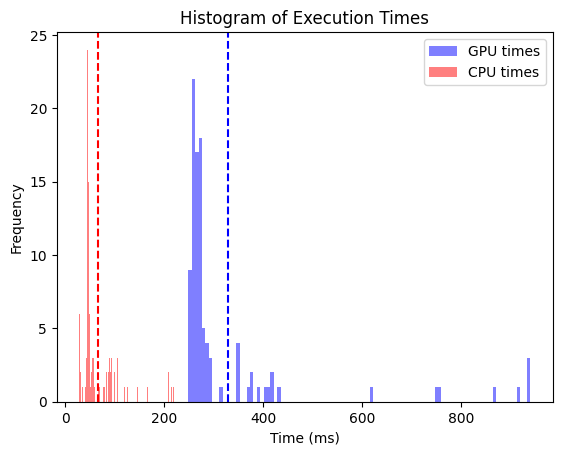

In [ ]:
# histogram of the durations
if testing_t:
  plt.hist(avg_gpu_times, bins=100, color='blue', alpha=0.5, label='GPU times')
  plt.hist(avg_cpu_times, bins=100, color='red', alpha=0.5, label='CPU times')
  plt.axvline(np.mean(avg_gpu_times), color='blue', linestyle='--') # vertical line for the mean
  plt.axvline(np.mean(avg_cpu_times), color='red', linestyle='--') # vertical line for the mean
  plt.xlabel('Time (ms)')
  plt.ylabel('Frequency')
  plt.title('Histogram of Execution Times')
  plt.legend()
  plt.show()
else:
  print("Set testing_t to True")